# 04_feature_importance: Step 4 - feature importance of the deployed surrogate.

```
* SHAP (TreeExplainer, Lundberg & Lee 2017): mean |SHAP| over all hourly samples,
  plus mean |SHAP| inside HVAC operating hours (the regime the optimiser uses).
* Permutation importance on the held-out test days (drop in R2, 50 repeats).
Outputs -> outputs/importance/feature_importance.csv and figures.
```

Dikonversi dari `scripts/04_feature_importance.py`. Jalankan dari folder `notebooks/`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import shap
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().resolve().parent   # notebook runs from AI-OBEP-MLPaper/notebooks
sys.path.insert(0, str(ROOT / "src"))
from obep_mlpaper.data import FEATURES, TARGET, day_split, hourly_dataset
from obep_mlpaper.plotstyle import INK2, SERIES, plt
from obep_mlpaper.surrogate import Surrogate

LABELS = {
    "air_temperature": "Indoor air temperature", "indoor_relative_humidity": "Indoor RH",
    "occupant_count": "Occupant count", "dry_bulb_temp": "Outdoor dry-bulb T",
    "outdoor_relative_humidity": "Outdoor RH", "wind_speed": "Wind speed",
    "global_horizontal_solar_radiation": "Solar radiation (GHI)", "hour_sin": "Hour of day (sin)",
    "hour_cos": "Hour of day (cos)", "hvac_schedule": "HVAC schedule (on/off)",
}
out = ROOT / "outputs" / "importance"
fig_dir = ROOT / "outputs" / "figures"
out.mkdir(parents=True, exist_ok=True)

sur = Surrogate.load(ROOT / "outputs" / "models" / "surrogate.joblib")
model = sur.model
d = hourly_dataset()
tr, te = day_split(d)
X = d[FEATURES].to_numpy()
y = d[TARGET].to_numpy()
op = d["hvac_schedule"].to_numpy() == 1

# TreeSHAP via xgboost's native implementation (identical values to shap.TreeExplainer;
# shap 0.49 cannot parse the base_score format written by xgboost >= 3)
import xgboost as xgb
sv = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]
perm = permutation_importance(model, X[te], y[te], scoring="r2", n_repeats=50, random_state=0, n_jobs=1)

imp = pd.DataFrame({
    "feature": FEATURES, "label": [LABELS[f] for f in FEATURES],
    "mean_abs_shap_all_hours": np.abs(sv).mean(0),
    "mean_abs_shap_operating_hours": np.abs(sv[op]).mean(0),
    "permutation_r2_drop_mean": perm.importances_mean, "permutation_r2_drop_std": perm.importances_std,
}).sort_values("mean_abs_shap_all_hours", ascending=False)
imp["shap_share_pct"] = 100 * imp.mean_abs_shap_all_hours / imp.mean_abs_shap_all_hours.sum()
imp["paper_feature"] = imp.feature.isin(FEATURES[:7])
imp.to_csv(out / "feature_importance.csv", index=False)
print(imp.round(4).to_string(index=False))

                          feature                  label  mean_abs_shap_all_hours  mean_abs_shap_operating_hours  permutation_r2_drop_mean  permutation_r2_drop_std  shap_share_pct  paper_feature
                    hvac_schedule HVAC schedule (on/off)               115.774498                     136.882004                    1.0632                   0.1081       65.524399          False
                   occupant_count         Occupant count                10.346100                      12.537300                    0.0231                   0.0071        5.855500           True
global_horizontal_solar_radiation  Solar radiation (GHI)                 9.991800                      10.995200                    0.0065                   0.0046        5.655000           True
                         hour_cos      Hour of day (cos)                 8.658900                       7.374600                    0.0300                   0.0092        4.900600          False
                       wi

In [2]:
# --- bar chart: SHAP (all hours vs operating hours) and permutation, sorted by SHAP
order = imp.iloc[::-1]
fig, ax = plt.subplots(1, 2, figsize=(9.0, 3.8), sharey=True)
yy = np.arange(len(order))
h = 0.38
ax[0].barh(yy + h / 2, order.mean_abs_shap_all_hours, h, color=SERIES[0], label="All hours")
ax[0].barh(yy - h / 2, order.mean_abs_shap_operating_hours, h, color=SERIES[1], label="HVAC operating hours")
ax[0].set(yticks=yy, yticklabels=order.label, xlabel="Mean |SHAP| [W/m²]", title="SHAP importance")
ax[0].legend(loc="lower right", fontsize=8)
ax[1].barh(yy, order.permutation_r2_drop_mean, 0.6, xerr=order.permutation_r2_drop_std,
           color=SERIES[0], error_kw=dict(ecolor=INK2, lw=1))
ax[1].set(xlabel="Drop in test R² when permuted", title="Permutation importance (held-out days)")
fig.tight_layout()
fig.savefig(fig_dir / "fig_feature_importance.png")

In [3]:
# --- SHAP beeswarm (direction of effects)
plt.figure()
shap.summary_plot(sv, pd.DataFrame(X, columns=[LABELS[f] for f in FEATURES]), show=False,
                  plot_size=(6.5, 4.2))
plt.title("SHAP values of the deployed surrogate")
plt.savefig(fig_dir / "fig_shap_beeswarm.png")
print("figures ->", fig_dir)

figures -> C:\Users\yohan\OneDrive - mail.unnes.ac.id\Penelitian AI-OBEP\AI-OBEP\AI-OBEP\AI-OBEP-MLPaper\outputs\figures


## Gambar yang dihasilkan

fig_feature_importance.png


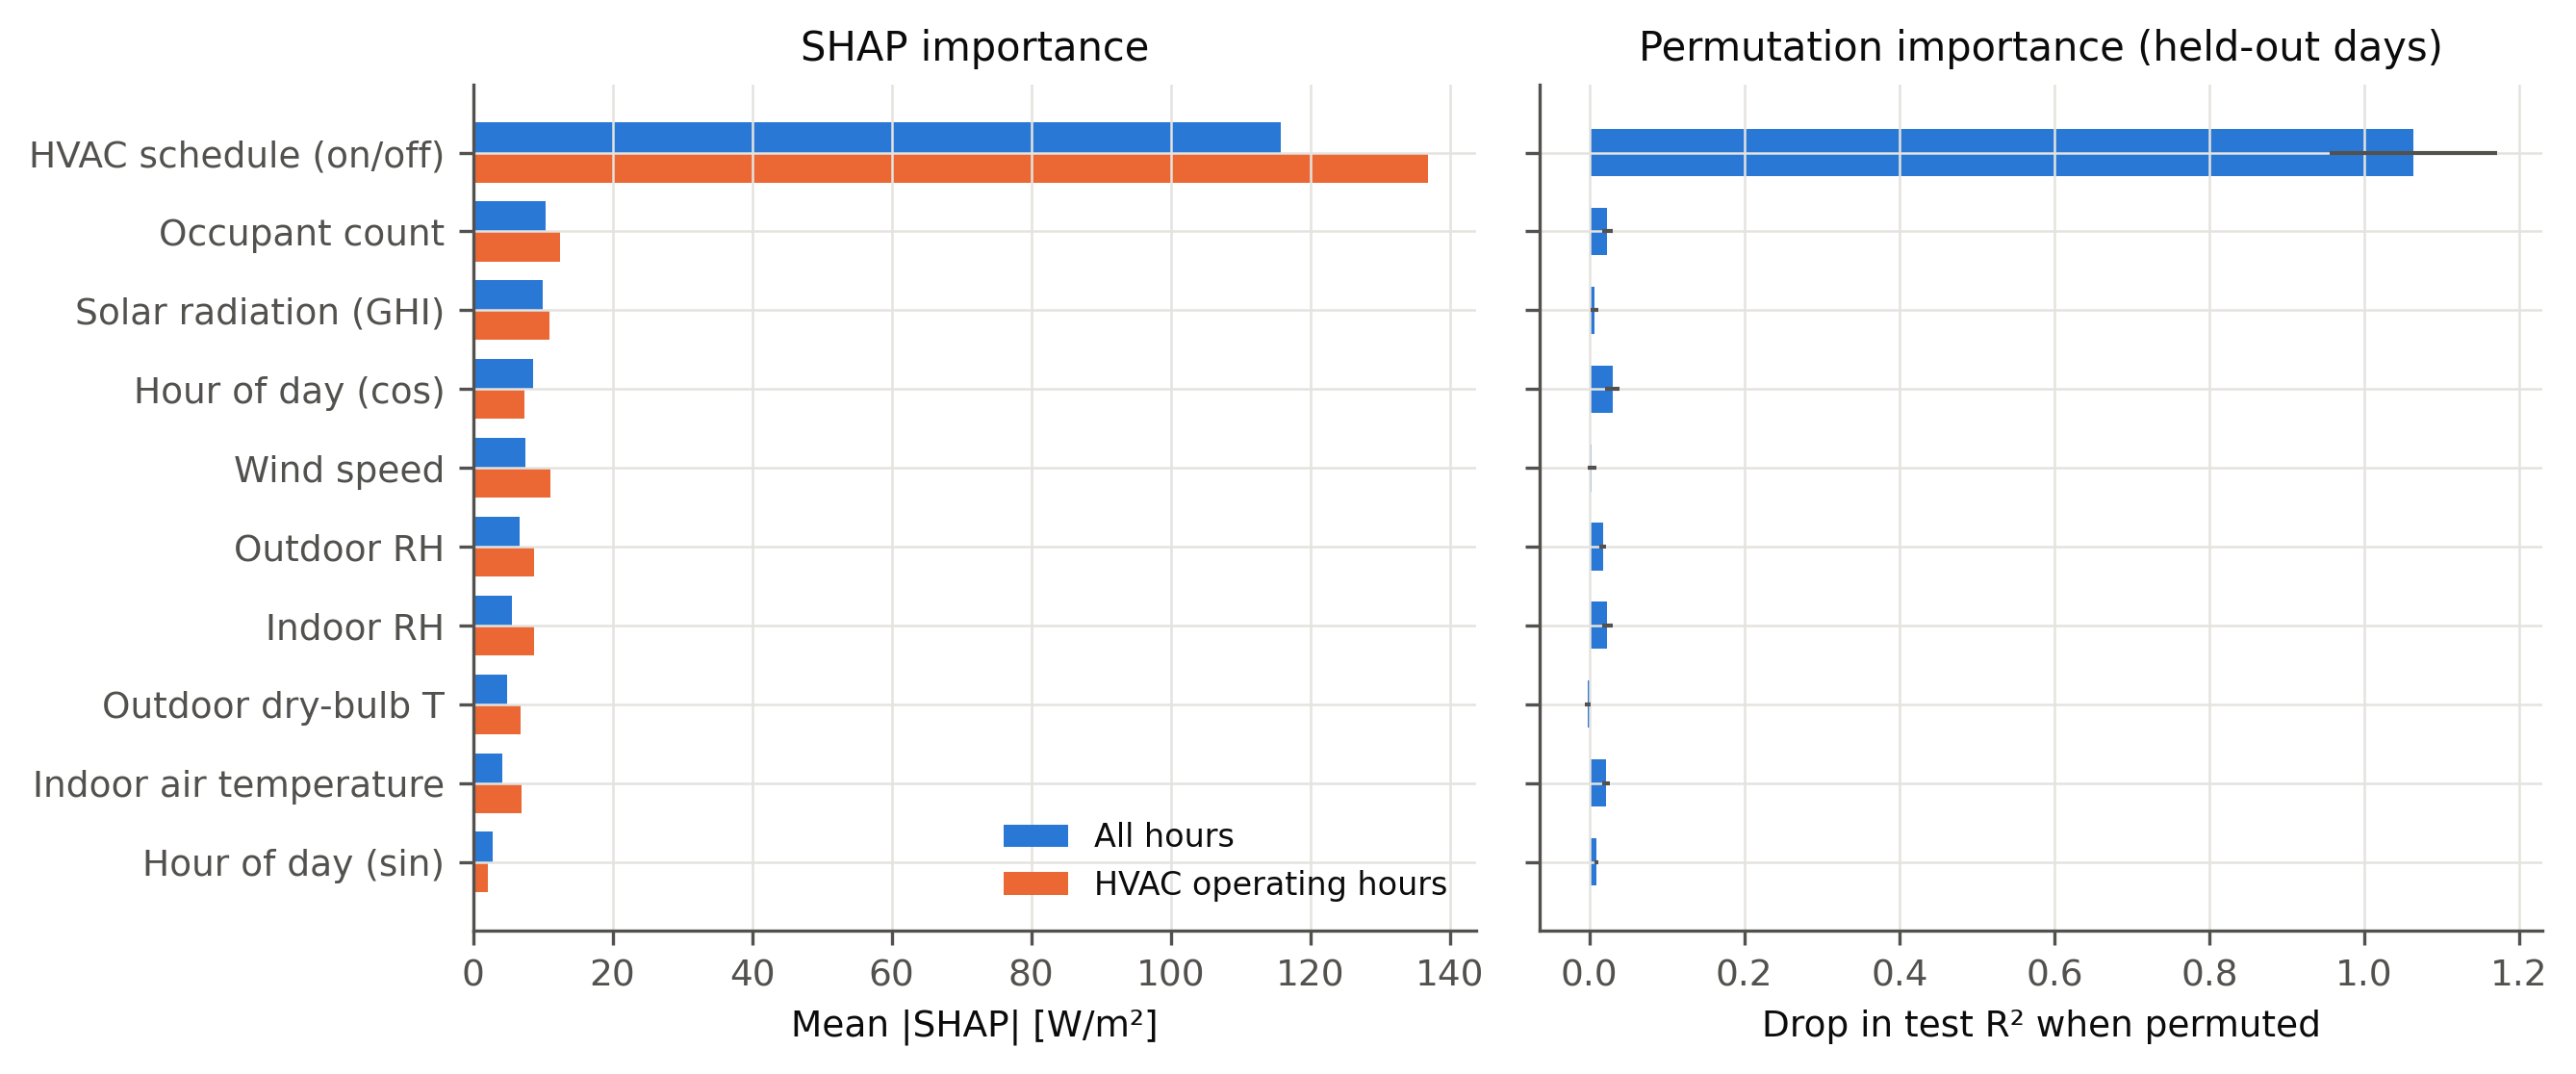

fig_shap_beeswarm.png


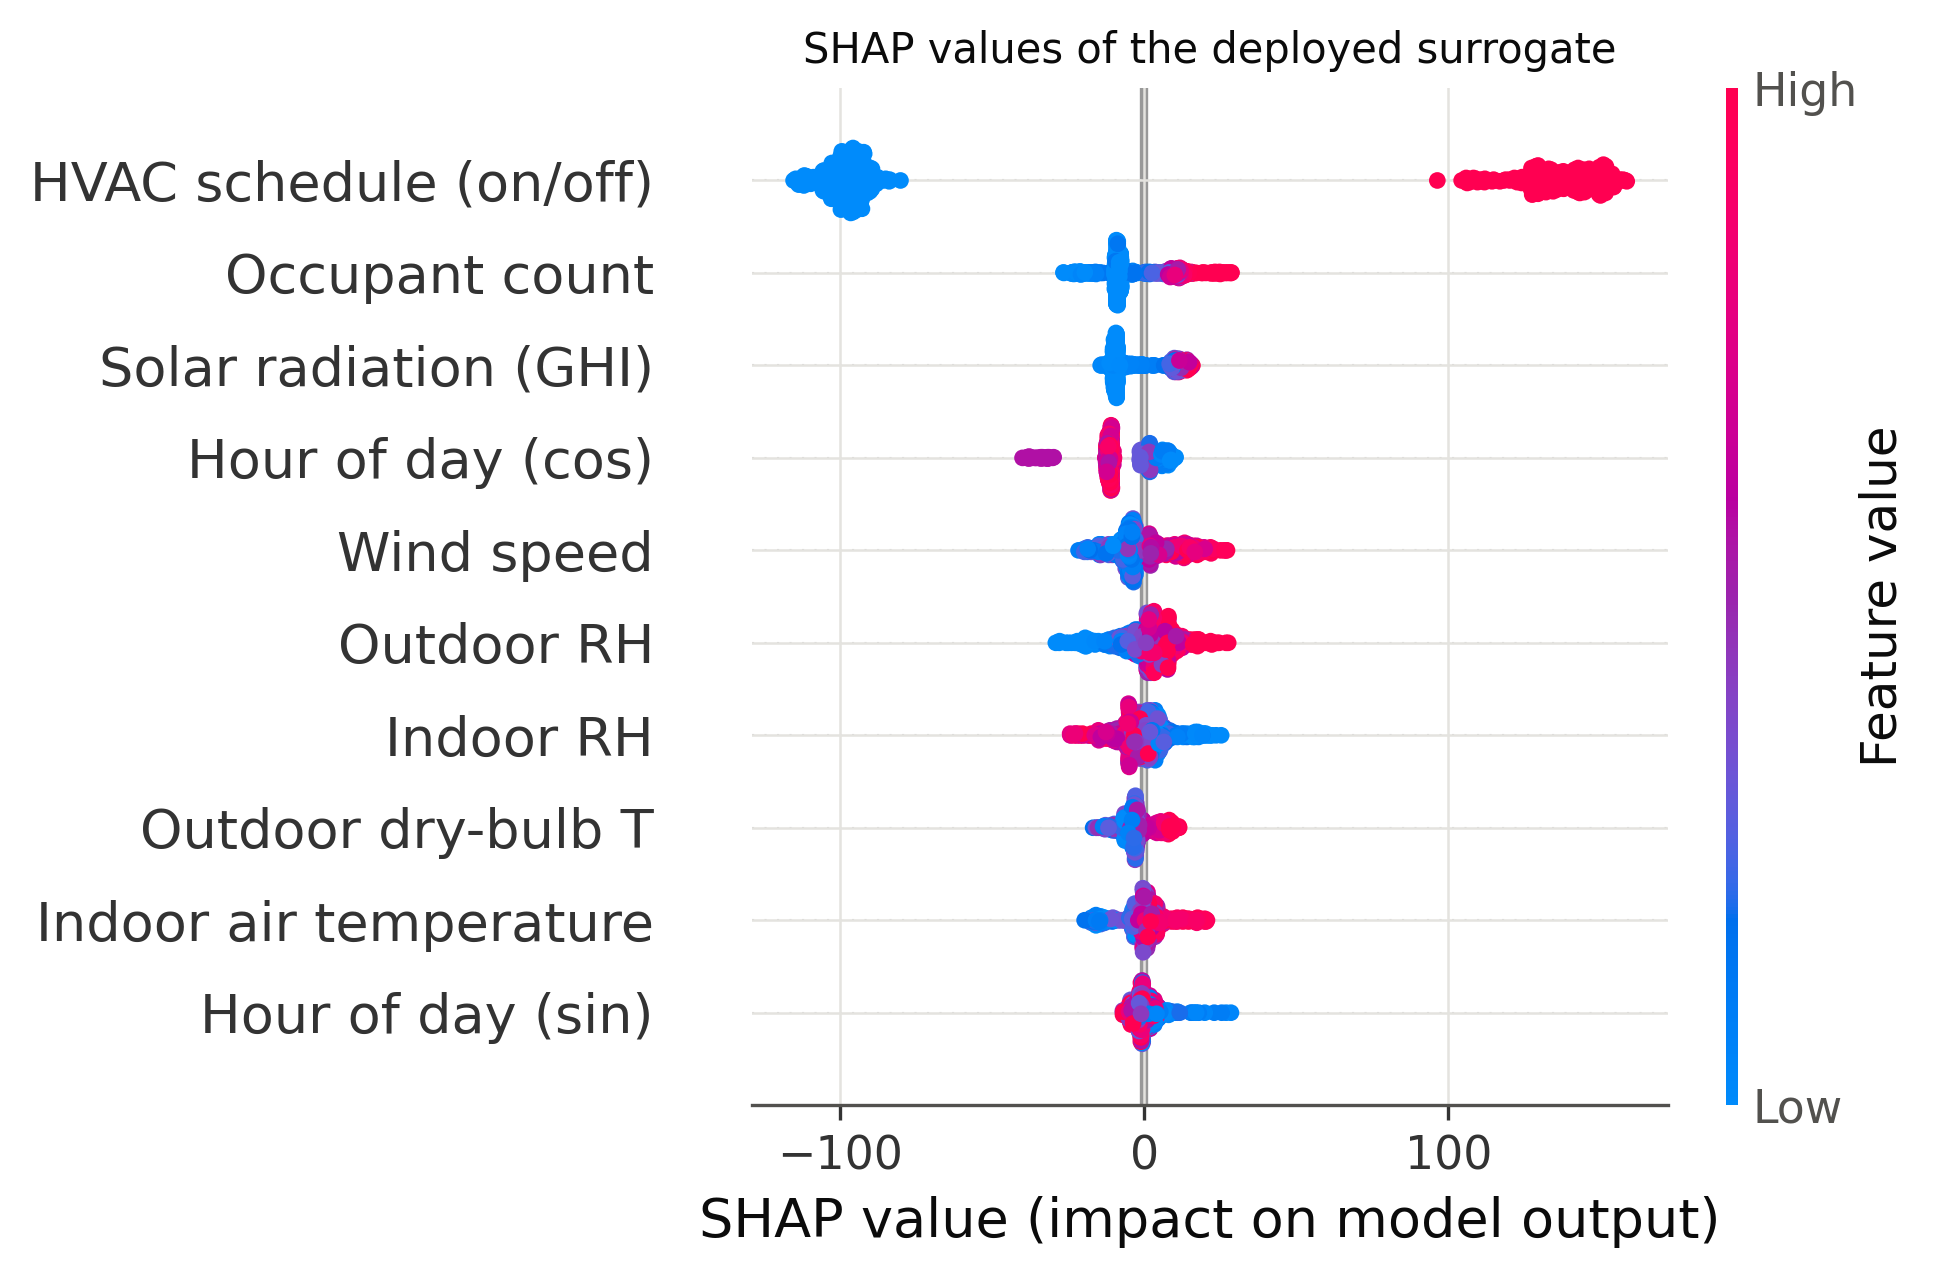

In [4]:
from IPython.display import Image, display
for f in ['fig_feature_importance.png', 'fig_shap_beeswarm.png']:
    print(f)
    display(Image(filename=str(ROOT / 'outputs' / 'figures' / f), width=800))